Explained variance ratio (PC1, PC2): [0.63853014 0.33366378]
Cumulative variance (2D): 0.9721939208277963
Separation score along Pore size: 0.358
Separation score along Contact angle: 7.603
Separation score along Thickness: 15.760
Separation score along PC1: 16.204


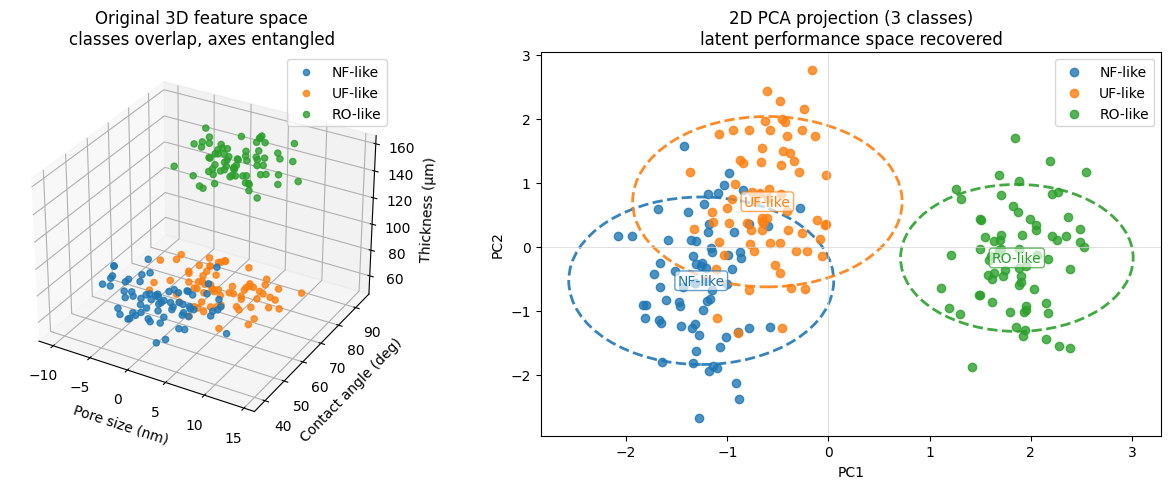

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from matplotlib.patches import Circle
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

rng = np.random.RandomState(0)

# ------------------------------------------------------------
# 1) Latent 2D "membrane performance" space with 3 clusters
#    Z ~ 2D space where NF / UF / RO are clearly separated.
# ------------------------------------------------------------
n_per_class = 70

# centers in latent space (arbitrary but well-separated)
mu_nf = np.array([-2.0,  0.0])
mu_uf = np.array([ 0.0,  2.0])
mu_ro = np.array([ 2.0, -1.5])

cov_latent = np.array([[0.5, 0.1],
                       [0.1, 0.5]])

Z_nf = rng.multivariate_normal(mu_nf, cov_latent, size=n_per_class)
Z_uf = rng.multivariate_normal(mu_uf, cov_latent, size=n_per_class)
Z_ro = rng.multivariate_normal(mu_ro, cov_latent, size=n_per_class)

Z = np.vstack([Z_nf, Z_uf, Z_ro])
y = np.array(
    [0] * n_per_class +
    [1] * n_per_class +
    [2] * n_per_class
)

class_names = {0: "NF-like", 1: "UF-like", 2: "RO-like"}
colors      = {0: "tab:blue", 1: "tab:orange", 2: "tab:green"}

# ------------------------------------------------------------
# 2) Map latent 2D → 3D "physical" features with mixing matrix
#    X = Z @ W^T + base_offsets + noise
#    Columns ~ [pore size, contact angle, thickness]
# ------------------------------------------------------------
W = np.array([
    [ 0.7,  0.2],   # pore size depends on both latent dims
    [ 3.0, -1.5],   # contact angle mixes dims strongly
    [ 8.0,  4.0]    # thickness also a combination
])

# class-dependent base offsets (roughly plausible ranges)
base_nf = np.array([1.0, 60.0,  90.0])
base_uf = np.array([5.0, 65.0,  70.0])
base_ro = np.array([0.4, 75.0, 130.0])

base_offsets = np.vstack([
    np.repeat(base_nf[None, :], n_per_class, axis=0),
    np.repeat(base_uf[None, :], n_per_class, axis=0),
    np.repeat(base_ro[None, :], n_per_class, axis=0),
])

X_clean = Z @ W.T + base_offsets
noise   = rng.normal(0, 4.0, size=X_clean.shape)  # isotropic measurement noise
X       = X_clean + noise  # final 3D "experimental" features

# ------------------------------------------------------------
# Helper: simple 1D separation score (Fisher-like)
# ------------------------------------------------------------
def separation_score_1d(values, labels):
    """
    Between-class variance / within-class variance along 1D.
    Larger => better class separation along that axis.
    """
    overall_mean = values.mean()
    unique = np.unique(labels)

    between = 0.0
    within  = 0.0
    for cls in unique:
        mask = (labels == cls)
        cls_vals = values[mask]
        cls_mean = cls_vals.mean()
        between += len(cls_vals) * (cls_mean - overall_mean) ** 2
        within  += ((cls_vals - cls_mean) ** 2).sum()

    return between / (within + 1e-8)

# ------------------------------------------------------------
# 3) PCA: standardize and reduce 3D → 2D
# ------------------------------------------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2, random_state=0)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio (PC1, PC2):", pca.explained_variance_ratio_)
print("Cumulative variance (2D):", pca.explained_variance_ratio_.sum())

# Compare separation along raw features vs PC1
feat_names = ["Pore size", "Contact angle", "Thickness"]
for i in range(3):
    score = separation_score_1d(X[:, i], y)
    print(f"Separation score along {feat_names[i]}: {score:.3f}")

pc1_score = separation_score_1d(X_pca[:, 0], y)
print(f"Separation score along PC1: {pc1_score:.3f}")

# ------------------------------------------------------------
# 4) 3D scatter (raw features) vs 2D PCA with circles
# ------------------------------------------------------------
fig = plt.figure(figsize=(13, 5))

# 3D: original correlated features (overlap + weird orientation)
ax3d = fig.add_subplot(1, 2, 1, projection="3d")
for cls in np.unique(y):
    mask = (y == cls)
    ax3d.scatter(
        X[mask, 0], X[mask, 1], X[mask, 2],
        c=colors[cls], label=class_names[cls], alpha=0.8
    )

ax3d.set_xlabel("Pore size (nm)")
ax3d.set_ylabel("Contact angle (deg)")
ax3d.set_zlabel("Thickness (µm)")
ax3d.set_title("Original 3D feature space\nclasses overlap, axes entangled")
ax3d.legend()

# 2D: PCA projection, clearer clustering in PC1–PC2
ax2d = fig.add_subplot(1, 2, 2)
for cls in np.unique(y):
    mask = (y == cls)
    pts = X_pca[mask]

    ax2d.scatter(
        pts[:, 0], pts[:, 1],
        c=colors[cls], label=class_names[cls], alpha=0.8
    )

    # circle around each cluster in PC space
    center = pts.mean(axis=0)
    dists  = np.linalg.norm(pts - center, axis=1)
    radius = 1.6 * dists.mean()  # tune factor for visibility

    circ = Circle(
        xy=center, radius=radius,
        edgecolor=colors[cls],
        facecolor="none",
        linewidth=2,
        linestyle="--",
        alpha=0.9
    )
    ax2d.add_patch(circ)

    ax2d.text(
        center[0], center[1],
        class_names[cls],
        color=colors[cls],
        fontsize=10,
        ha="center",
        va="center",
        bbox=dict(boxstyle="round,pad=0.2",
                  fc="white", ec=colors[cls], alpha=0.7)
    )

ax2d.set_xlabel("PC1")
ax2d.set_ylabel("PC2")
ax2d.set_title("2D PCA projection (3 classes)\nlatent performance space recovered")
ax2d.axhline(0, color="lightgray", linewidth=0.5)
ax2d.axvline(0, color="lightgray", linewidth=0.5)
ax2d.legend(loc="upper right")

plt.tight_layout()
plt.show()